# SCAN: clustering on top of SimCLR or ImageNet ResNet-50

Van Gansbeke et al., 2020 (*SCAN: Learning to Classify Images without Labels*).

SimCLR puts similar paintings **near** each other but spreads everything evenly, so the embedding is a continuous cloud and K-means has to cut it arbitrarily. SCAN turns "near" into "same cluster":

1. **Mine neighbours**: the `N_NEIGHBORS` nearest paintings of every painting in the SimCLR space.
2. **SCAN training**: clustering heads (softmax over `K`). Each painting and a random one of its neighbours must get the **same** cluster:
   `loss = -log <p(anchor), p(neighbour)>  -  ENTROPY_WEIGHT * H(mean p)`.
   The entropy term keeps all clusters in use (without it everything goes into one cluster).
3. **Self-labelling**: paintings the model is very sure about (`max p > CONFIDENCE`) become pseudo-labels; training on them with augmented views sharpens the clusters.

**Two modes** (`MODE`):
* `"frozen"` (default, cheap): the SimCLR encoder is **not** trained. Every painting is embedded once without augmentation and `N_VIEWS` times with the strong augmentation; SCAN and self-labelling then train small heads on these cached vectors. Cost: `1 + N_VIEWS` inference passes over the data (roughly one SimCLR training epoch), then seconds per epoch.
* `"finetune"` (paper setup, expensive): the encoder is fine-tuned on images. **Every SCAN epoch costs about one SimCLR epoch**, so keep `N_PAINTINGS` and the epoch counts small.

**Representation** (`SOURCE`):
* `"simclr"`: your SimCLR checkpoint (`SAVE_TO` of `simclr_clustering.ipynb`, or one of its snapshots), 128 px;
* `"imagenet"`: torchvision ResNet-50 with supervised ImageNet weights, 224 px, the same features as `resnet_feature_clustering.ipynb`. Pretrained on labels, so report it as a separate category. Use `MODE = "frozen"` (fine-tuning ResNet-50 at 224 px does not fit a 6 GB GPU comfortably).

In frozen mode the clean and augmented embeddings are cached in `CACHE_DIR`, so a second run (other `K`, entropy weight, ...) skips the embedding passes.

In [37]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from torch.utils.data import DataLoader, Subset
from torchvision.ops import roi_align
from torchvision.transforms import v2
from tqdm.auto import tqdm

if "google.colab" in sys.modules:
    SRC = Path("/content/Project/src")          # or /content/drive/MyDrive/.../Project/src
else:
    SRC = Path.cwd().parents[1]                 # training/ -> restore_pipeline/ -> src/

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from restore_pipeline.dataprocessing.dataloading import RESIZE_128, DataConfig, get_splits, get_splits_dataloaders
from restore_pipeline.clustering.plotting import plot_cluster_samples, plot_clusters_2d, umap_project

# Config

In [38]:
# ---------------- Data ----------------
DATA_DIR    = Path("../data")
BATCH_SIZE  = 128                 # images per batch when embedding (and when fine-tuning)
NUM_WORKERS = 4
SEED        = 42

SPLIT         = "train"           # use the split SimCLR was trained on
N_PAINTINGS   = None              # None = whole split
LABEL_COLUMNS = ["style", "genre", "artist"]   # metadata for evaluation only (never used in training)

# ---------------- Representation ----------------
SOURCE            = "simclr"    # "simclr" (your checkpoint) | "imagenet" (torchvision, supervised ImageNet weights)
SIMCLR_CHECKPOINT = Path("checkpoints_simclr_resnet_full_hard") / "simclr_resnet_full_hard.pt"   # SOURCE = "simclr". Or .../..._snapshots/epoch_100.pt
IMAGENET_BACKBONE = "resnet50"    # SOURCE = "imagenet": "resnet18" | "resnet50" | ...
IMG_SIZE = 224 if SOURCE == "imagenet" else 128      # ImageNet nets: their training resolution. SimCLR: what it was trained on
PCA_DIM  = 64 if SOURCE == "imagenet" else None      # neighbour mining / K-means features: as in resnet_feature_clustering (64) / simclr_clustering (None)
CACHE_DIR = Path("features")      # frozen mode: clean + augmented embeddings are saved here and reused (None = off)

def make_preprocess():
    """Embedding -> features for neighbour mining and the K-means baseline (same as in the notebook the representation comes from)."""
    steps = [PCA(PCA_DIM, whiten=True, random_state=SEED)] if PCA_DIM else []
    return make_pipeline(*steps, Normalizer(norm="l2"))

# ---------------- Mode ----------------
MODE = "frozen"                   # "frozen" (cheap: cached embeddings, only heads trained) | "finetune" (paper: encoder trained too, slow)
N_VIEWS     = 4                   # frozen: augmented embeddings cached per painting. Cost = (1 + N_VIEWS) inference passes. GPU memory: n * dim * N_VIEWS * 2 bytes (82k, 4 views: 512-d ~ 0.3 GB, ResNet-50 2048-d ~ 1.35 GB)
HEAD_HIDDEN = 512                 # frozen: hidden layer of each head (0 = linear head). An MLP makes up a bit for the frozen encoder

# ---------------- SCAN ----------------
K              = 20               # number of clusters. The entropy term pushes towards EQUAL sizes: very large K splits big genres
N_NEIGHBORS    = 20               # paper: 20
ENTROPY_WEIGHT = 5.0              # paper: 5. Lower -> unequal cluster sizes allowed (risk: a few clusters take everything)
N_HEADS        = 5                # several heads trained at once; the one with the lowest loss is kept (paper: 10)
if MODE == "frozen":              # one epoch = a few hundred tiny MLP steps: seconds
    SCAN_EPOCHS, SELF_EPOCHS, LR, HEAD_BATCH = 100, 50, 1e-3, 512
else:                             # one epoch ~ one SimCLR epoch: hours on the whole split -> keep these small
    SCAN_EPOCHS, SELF_EPOCHS, LR, HEAD_BATCH = 10, 5, 1e-4, BATCH_SIZE

# ---------------- Self-labelling ----------------
SELF_LABEL = True
CONFIDENCE = 0.99                 # paper: 0.99. Lower it (e.g. 0.9) if (almost) nothing passes
MIN_CLUSTERS = 0.8                # self-labelling stops and rolls back to the last good head if fewer than this share of K clusters stays in use (collapse)

# ---------------- Augmentations (strong = SimCLR-like; weak only used in finetune mode) ----------------
CROP_SCALE     = (0.2, 1.0)
COLOR_STRENGTH = 0.5
P_COLOR        = 0.8
P_GRAY         = 0.2

# ---------------- Evaluation ----------------
EVAL_EVERY    = 10 if MODE == "frozen" else 2   # epochs between AMI checks of the best head
SHOW_CLUSTERS = 12                # sample grid: only the largest clusters
SAVE_TO       = None              # e.g. SIMCLR_CHECKPOINT.parent / "scan_k20.pt"

USE_AMP = True
device = "cuda" if torch.cuda.is_available() else "cpu"
AMP = USE_AMP and device == "cuda" and torch.cuda.is_bf16_supported()
assert MODE in ("frozen", "finetune"), MODE
assert SOURCE in ("simclr", "imagenet"), SOURCE
if SOURCE == "simclr":
    assert Path(SIMCLR_CHECKPOINT).exists(), f"{SIMCLR_CHECKPOINT} not found: run simclr_clustering.ipynb with SAVE_TO set first"
REPR_NAME = f"SimCLR {Path(SIMCLR_CHECKPOINT).parent.name}/{Path(SIMCLR_CHECKPOINT).stem}" if SOURCE == "simclr" else f"{IMAGENET_BACKBONE} (ImageNet)"
MODEL_TAG = f"{Path(SIMCLR_CHECKPOINT).parent.name}_{Path(SIMCLR_CHECKPOINT).stem}" if SOURCE == "simclr" else IMAGENET_BACKBONE
CACHE_TAG = (f"{SOURCE}_{MODEL_TAG}_{SPLIT}_{N_PAINTINGS}_{IMG_SIZE}px"
             f"_crop{CROP_SCALE[0]}-{CROP_SCALE[1]}_s{COLOR_STRENGTH}_seed{SEED}")
RUN_NAME = f"SCAN {MODE} on {REPR_NAME} (K={K}, {N_NEIGHBORS} neighbours, entropy {ENTROPY_WEIGHT})"

# Data

Images are streamed in a fixed order by `image_loader` (row i = painting `cluster_idx[i]`).
Only in `finetune` mode are they also cached in RAM (uint8), because training needs a painting **and** one of its neighbours in every batch (82k paintings at 128 px ~ 4 GB of RAM).

In [39]:
# Images in [0, 1] (the augmentations work on those); ImageNet normalisation happens inside the encoder
TRANSFORM = RESIZE_128 if IMG_SIZE == 128 else v2.Compose([
    v2.ToImage(),
    v2.Resize((IMG_SIZE, IMG_SIZE), antialias=True),     # whole painting squashed, no centre crop (as in resnet_feature_clustering)
    v2.ToDtype(torch.float32, scale=True),
])

data_cfg = DataConfig(
    processed_path=DATA_DIR / "wikiart_train_processed",
    cache_dir=str(DATA_DIR),
    seed=SEED,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    shuffle_train=False,
    transform_train=TRANSFORM,
    transform_val=TRANSFORM,
    transform_test=TRANSFORM,
    transform_full=TRANSFORM,
)
splits = dict(zip(["train", "val", "test"], get_splits(data_cfg)))                    # raw rows: images + metadata
image_datasets = {name: loader.dataset                                                # transformed images only
                  for name, loader in zip(["train", "val", "test"], get_splits_dataloaders(data_cfg))}


def sample_indices(n_total: int, n: int | None) -> np.ndarray:
    """`n` random row indices, sorted (rows keep dataset order). All rows if `n` is None."""
    if n is None or n >= n_total:
        return np.arange(n_total)
    return np.sort(np.random.default_rng(SEED).choice(n_total, size=n, replace=False))


cluster_idx = sample_indices(len(image_datasets[SPLIT]), N_PAINTINGS)
image_loader = DataLoader(Subset(image_datasets[SPLIT], cluster_idx.tolist()), batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=False, persistent_workers=NUM_WORKERS > 0)

# Row i of every embedding / label array is painting cluster_idx[i]
ds_cluster = splits[SPLIT].select(cluster_idx)
meta = ds_cluster.select_columns(LABEL_COLUMNS).to_pandas()
n_paintings = len(cluster_idx)
print(f"{SPLIT}: {n_paintings} paintings")

if MODE == "finetune":
    images_u8 = torch.cat([(batch["image"] * 255).round().to(torch.uint8) for batch in tqdm(image_loader, desc="caching images")])
    print(f"cached {images_u8.numel() / 1e9:.2f} GB of images")


def load(positions) -> torch.Tensor:
    """finetune mode: rows of images_u8 -> float images in [0, 1] on the GPU."""
    positions = torch.as_tensor(positions, dtype=torch.long)
    return images_u8[positions].to(device, non_blocking=True).float().div_(255)

train: 82321 paintings


# Augmentations

The SimCLR augmentations (per-image random crop, flip, colour jitter, grayscale, batched on the GPU) are the **strong** ones.
The **weak** one (light crop + flip) is used in self-labelling to decide the pseudo-labels.

In [40]:
LUMA = torch.tensor([0.299, 0.587, 0.114], device=device).view(1, 3, 1, 1)
RGB_TO_YIQ = torch.tensor([[0.299, 0.587, 0.114],
                           [0.596, -0.274, -0.322],
                           [0.211, -0.523, 0.312]], device=device)
YIQ_TO_RGB = torch.linalg.inv(RGB_TO_YIQ)


def uniform(n: int, low: float, high: float) -> torch.Tensor:
    return torch.empty(n, device=device).uniform_(low, high)


def random_resized_crop(x: torch.Tensor, scale: tuple, ratio: tuple = (3 / 4, 4 / 3)) -> torch.Tensor:
    b, _, h, w = x.shape
    area = uniform(b, *scale) * h * w
    aspect = torch.exp(uniform(b, math.log(ratio[0]), math.log(ratio[1])))
    crop_w = torch.sqrt(area * aspect).clamp(max=w)
    crop_h = torch.sqrt(area / aspect).clamp(max=h)
    x0 = torch.rand(b, device=device) * (w - crop_w)
    y0 = torch.rand(b, device=device) * (h - crop_h)
    boxes = torch.stack([torch.arange(b, device=device, dtype=x.dtype), x0, y0, x0 + crop_w, y0 + crop_h], dim=1)
    return roi_align(x, boxes, output_size=(h, w), spatial_scale=1.0, sampling_ratio=1, aligned=True)


def gray(x: torch.Tensor) -> torch.Tensor:
    return (x * LUMA).sum(dim=1, keepdim=True)


def color_jitter(x: torch.Tensor, s: float) -> torch.Tensor:
    b = len(x)
    view = lambda t: t.view(b, 1, 1, 1)
    y = x * view(uniform(b, 1 - 0.8 * s, 1 + 0.8 * s))                                  # brightness
    mean = gray(y).mean(dim=(2, 3), keepdim=True)
    y = (y - mean) * view(uniform(b, 1 - 0.8 * s, 1 + 0.8 * s)) + mean                    # contrast
    g = gray(y)
    y = (y - g) * view(uniform(b, 1 - 0.8 * s, 1 + 0.8 * s)) + g                          # saturation
    theta = uniform(b, -0.2 * s, 0.2 * s) * 2 * math.pi                                   # hue: rotate the I/Q chroma plane
    cos, sin = torch.cos(theta), torch.sin(theta)
    rot = torch.zeros(b, 3, 3, device=device)
    rot[:, 0, 0] = 1
    rot[:, 1, 1], rot[:, 1, 2], rot[:, 2, 1], rot[:, 2, 2] = cos, -sin, sin, cos
    m = YIQ_TO_RGB @ rot @ RGB_TO_YIQ
    return torch.einsum("bij,bjhw->bihw", m, y).clamp(0, 1)


def flip(x: torch.Tensor) -> torch.Tensor:
    return torch.where((torch.rand(len(x), device=device) < 0.5).view(-1, 1, 1, 1), x.flip(dims=[3]), x)


def strong_augment(x: torch.Tensor) -> torch.Tensor:
    b = len(x)
    pick = lambda p: (torch.rand(b, device=device) < p).view(b, 1, 1, 1)
    x = flip(random_resized_crop(x, CROP_SCALE))
    x = torch.where(pick(P_COLOR), color_jitter(x, COLOR_STRENGTH), x)
    x = torch.where(pick(P_GRAY), gray(x).expand(-1, 3, -1, -1), x)
    return x


def weak_augment(x: torch.Tensor) -> torch.Tensor:
    return flip(random_resized_crop(x, (0.8, 1.0)))

# Load the encoder

`simclr`: the encoder definition must match `simclr_clustering.ipynb` (copied here so the notebook is standalone); only the encoder is used, the projection head is dropped.
`imagenet`: torchvision weights, classifier replaced by `Identity` (pooled features), ImageNet normalisation as the first layer.

`cached(name, compute)` saves embeddings to `CACHE_DIR` (fp16) and loads them on the next run.

In [41]:
def conv_bn_relu(c_in: int, c_out: int) -> list[nn.Module]:
    return [nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True)]


def make_encoder(name: str) -> tuple[nn.Module, int]:
    if name == "resnet18":
        net = torchvision.models.resnet18(weights=None)
        net.fc = nn.Identity()
        return net, 512
    if name == "small_cnn":
        return nn.Sequential(
            *conv_bn_relu(3, 64), nn.MaxPool2d(2),
            *conv_bn_relu(64, 128), nn.MaxPool2d(2),
            *conv_bn_relu(128, 256), *conv_bn_relu(256, 256), nn.MaxPool2d(2),
            *conv_bn_relu(256, 512), *conv_bn_relu(512, 512), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
        ), 512
    raise ValueError(f"unknown BACKBONE: {name}")


class ImageNetEncoder(nn.Module):
    """[0, 1] images -> ImageNet normalisation -> torchvision backbone without its classifier."""
    def __init__(self, name: str):
        super().__init__()
        self.net = torchvision.models.get_model(name, weights=torchvision.models.get_model_weights(name).DEFAULT)
        self.feat_dim = self.net.fc.in_features
        self.net.fc = nn.Identity()
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net((x - self.mean) / self.std)


if SOURCE == "simclr":
    checkpoint = torch.load(SIMCLR_CHECKPOINT, map_location="cpu", weights_only=False)   # the checkpoint also holds the training log (numpy floats)
    simclr_cfg = checkpoint["config"]
    encoder, FEAT_DIM = make_encoder(simclr_cfg["backbone"])
    encoder.load_state_dict({k.removeprefix("encoder."): v for k, v in checkpoint["state_dict"].items() if k.startswith("encoder.")})
    trained_epochs = checkpoint.get("epoch", simclr_cfg["epochs"])
    print(f"loaded {SIMCLR_CHECKPOINT}: {simclr_cfg['backbone']}, {trained_epochs} epochs on {simclr_cfg['n_paintings']} {simclr_cfg['split']} paintings")
    del checkpoint
else:
    encoder = ImageNetEncoder(IMAGENET_BACKBONE)
    FEAT_DIM = encoder.feat_dim
    simclr_cfg = {"backbone": f"{IMAGENET_BACKBONE} (ImageNet)"}
    print(f"{IMAGENET_BACKBONE} with ImageNet weights: {FEAT_DIM}-d features at {IMG_SIZE} px")
encoder = encoder.to(device).to(memory_format=torch.channels_last)
encoder.requires_grad_(MODE == "finetune")


@torch.inference_mode()
def embed_all(net: nn.Module, view=None, desc: str = "embedding") -> torch.Tensor:
    """Encoder output for every painting in image_loader order, optionally of an augmented view. (n, FEAT_DIM) float32 on the CPU."""
    net.eval()
    out = []
    for batch in tqdm(image_loader, desc=desc, leave=False):
        x = batch["image"].to(device, non_blocking=True)
        if view is not None:
            x = view(x)
        with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=AMP):
            out.append(net(x.contiguous(memory_format=torch.channels_last)).float().cpu())
    return torch.cat(out)


def cached(name: str, compute) -> torch.Tensor:
    """compute() -> (n, d) tensor, saved to / loaded from CACHE_DIR as fp16 .npy (None = no cache)."""
    if CACHE_DIR is None:
        return compute()
    file = Path(CACHE_DIR) / f"scan_{CACHE_TAG}_{name}.npy"
    if file.exists():
        print(f"loaded {file}")
        return torch.from_numpy(np.load(file).astype(np.float32))
    out = compute()
    file.parent.mkdir(parents=True, exist_ok=True)
    np.save(file, out.half().numpy())
    print(f"saved {file}")
    return out

loaded checkpoints_simclr_resnet_full_hard\simclr_resnet_full_hard.pt: resnet18, 200 epochs on None train paintings


# 1. Mining neighbours

Neighbours are found in the same features the representation's own notebook clustered (`make_preprocess`).

**Neighbour agreement** is the share of a painting's neighbours with the same genre / style. SCAN can only be as good as its neighbours: it is the most important diagnostic here, and roughly an upper bound of what SCAN can reach.
The chance level is what random "neighbours" would give.

In [42]:
clean_embed = cached("clean", lambda: embed_all(encoder, desc="embedding (no augmentation)"))
simclr_features = make_preprocess().fit_transform(clean_embed.numpy())
_, neighbors = NearestNeighbors(n_neighbors=N_NEIGHBORS + 1).fit(simclr_features).kneighbors(simclr_features)
neighbors = neighbors[:, 1:]                        # drop the painting itself
print(f"neighbours: {neighbors.shape}")

rows = []
for column in LABEL_COLUMNS:
    values = meta[column].to_numpy()
    known = meta[column].notna().to_numpy()
    same = (values[neighbors] == values[:, None])[known]
    shares = meta[column][known].value_counts(normalize=True).to_numpy()
    rows.append({"labels": column, "neighbour agreement": same.mean(), "chance": float((shares ** 2).sum())})
display(pd.DataFrame(rows).round(3))

embedding (no augmentation):   0%|          | 0/644 [00:23<?, ?it/s]

saved features\scan_simclr_checkpoints_simclr_resnet_full_hard_simclr_resnet_full_hard_train_None_128px_crop0.2-1.0_s0.5_seed42_clean.npy
neighbours: (82321, 20)


,labels,neighbour agreement,chance
0,style,0.199,0.048
1,genre,0.362,0.090
2,artist,0.078,0.002


In [43]:
# Baseline: K-means with the same K on the same features
kmeans_labels = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit_predict(simclr_features)

# 2. SCAN training

`N_HEADS` independent clustering heads; each gets its own loss, and the head with the lowest final loss is kept (heads differ only by their random initialisation). Heads take the L2-normalised encoder output.

* `frozen`: the augmented embeddings are computed once here (`N_VIEWS` passes); every training step picks a random cached view of the anchor and of its neighbour.
* `finetune`: every step augments the images and runs the encoder.

Logged per epoch, for the current best head: **consistency** (lower = anchors and neighbours agree more), **entropy** of the average assignment (maximum `log K` = all clusters equally used).

In [44]:
class ClusterHeads(nn.Module):
    def __init__(self, feat_dim: int, k: int, n_heads: int, hidden: int):
        super().__init__()
        def head():
            if hidden == 0:
                return nn.Linear(feat_dim, k)
            return nn.Sequential(nn.Linear(feat_dim, hidden), nn.BatchNorm1d(hidden), nn.ReLU(inplace=True), nn.Linear(hidden, k))
        self.heads = nn.ModuleList([head() for _ in range(n_heads)])

    def forward(self, h: torch.Tensor) -> list[torch.Tensor]:
        h = F.normalize(h.float(), dim=1)
        return [head(h) for head in self.heads]


def scan_loss(anchor_logits: torch.Tensor, neighbor_logits: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    p_anchor = F.softmax(anchor_logits.float(), dim=1)
    p_neighbor = F.softmax(neighbor_logits.float(), dim=1)
    consistency = -torch.log((p_anchor * p_neighbor).sum(dim=1).clamp_min(1e-7)).mean()
    mean_p = p_anchor.mean(dim=0)
    entropy = -(mean_p * mean_p.clamp_min(1e-8).log()).sum()
    return consistency - ENTROPY_WEIGHT * entropy, consistency, entropy


if MODE == "frozen":
    # (N_VIEWS, n, FEAT_DIM) augmented embeddings + the clean ones, kept on the GPU in bf16 / fp16
    store = torch.bfloat16 if AMP else torch.float16
    torch.manual_seed(SEED)
    views = torch.stack([cached(f"view{v}", lambda: embed_all(encoder, strong_augment, desc=f"augmented view {v + 1}/{N_VIEWS}")).to(device, store)
                         for v in range(N_VIEWS)])
    clean = clean_embed.to(device, store)
    print(f"cached {N_VIEWS} augmented views: {views.numel() * views.element_size() / 1e9:.2f} GB on {device}")


def features_of(positions: np.ndarray, aug: str) -> torch.Tensor:
    """Encoder output for these paintings. aug: "strong" | "weak" | "none". Gradients flow into the encoder only in finetune mode."""
    if MODE == "frozen":
        idx = torch.as_tensor(positions, device=device)
        if aug == "strong":
            return views[torch.randint(N_VIEWS, (len(idx),), device=device), idx].float()
        return clean[idx].float()                   # "weak" / "none": the clean embedding
    x = load(positions)
    x = strong_augment(x) if aug == "strong" else weak_augment(x) if aug == "weak" else x
    with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=AMP):
        return encoder(x.contiguous(memory_format=torch.channels_last)).float()


@torch.inference_mode()
def predict(head: int) -> np.ndarray:
    """Cluster probabilities of every painting (no augmentation)."""
    heads.eval()
    h = clean if MODE == "frozen" else embed_all(encoder).to(device)
    return torch.cat([F.softmax(heads(h[s:s + 4096])[head], dim=1).cpu() for s in range(0, n_paintings, 4096)]).numpy()


def ami(labels: np.ndarray, column: str) -> float:
    known = meta[column].notna().to_numpy()
    return adjusted_mutual_info_score(meta[column][known], labels[known])


def set_train() -> None:
    heads.train()
    encoder.train(MODE == "finetune")


torch.manual_seed(SEED)
heads = ClusterHeads(FEAT_DIM, K, N_HEADS, HEAD_HIDDEN if MODE == "frozen" else 0).to(device)
params = list(heads.parameters()) + (list(encoder.parameters()) if MODE == "finetune" else [])
optimizer = torch.optim.Adam(params, lr=LR, weight_decay=1e-4)
rng = np.random.default_rng(SEED)
n_batches = n_paintings // HEAD_BATCH
scan_log = []

for epoch in tqdm(range(1, SCAN_EPOCHS + 1), desc="SCAN epochs"):
    set_train()
    sums = np.zeros((N_HEADS, 3))
    order = rng.permutation(n_paintings)
    for b in tqdm(range(n_batches), desc=f"epoch {epoch}", leave=False, disable=MODE == "frozen"):
        anchors = order[b * HEAD_BATCH:(b + 1) * HEAD_BATCH]
        partners = neighbors[anchors, rng.integers(0, N_NEIGHBORS, size=len(anchors))]
        logits = heads(features_of(np.concatenate([anchors, partners]), "strong"))   # one pass: shared BatchNorm statistics
        losses = [scan_loss(l[:len(anchors)], l[len(anchors):]) for l in logits]
        total = sum(loss for loss, _, _ in losses)

        optimizer.zero_grad(set_to_none=True)
        total.backward()
        optimizer.step()
        sums += torch.tensor([[t.item() for t in parts] for parts in losses]).numpy()

    means = sums / n_batches
    best_head = int(means[:, 0].argmin())
    row = {"epoch": epoch, "best_head": best_head, "loss": means[best_head, 0],
           "consistency": means[best_head, 1], "entropy": means[best_head, 2]}
    if EVAL_EVERY and (epoch % EVAL_EVERY == 0 or epoch == SCAN_EPOCHS):
        labels_now = predict(best_head).argmax(axis=1)
        row |= {"ami_style": ami(labels_now, "style"), "ami_genre": ami(labels_now, "genre"),
                "clusters_used": len(np.unique(labels_now))}
        print(f"epoch {epoch}: head {best_head} | loss {row['loss']:.3f} | consistency {row['consistency']:.3f} | "
              f"entropy {row['entropy']:.3f} / {math.log(K):.3f} | AMI style {row['ami_style']:.3f} "
              f"genre {row['ami_genre']:.3f} | {row['clusters_used']} clusters used")
    scan_log.append(row)

scan_log = pd.DataFrame(scan_log)
scan_probs = predict(best_head)
scan_labels = scan_probs.argmax(axis=1)

# Snapshot of the SCAN result: self-labelling always starts from here, even when its cell is re-run
scan_head_state = {k: v.clone() for k, v in heads.heads[best_head].state_dict().items()}
scan_encoder_state = {k: v.clone() for k, v in encoder.state_dict().items()} if MODE == "finetune" else None

augmented view 1/4:   0%|          | 0/644 [00:00<?, ?it/s]

saved features\scan_simclr_checkpoints_simclr_resnet_full_hard_simclr_resnet_full_hard_train_None_128px_crop0.2-1.0_s0.5_seed42_view0.npy


augmented view 2/4:   0%|          | 0/644 [00:00<?, ?it/s]

saved features\scan_simclr_checkpoints_simclr_resnet_full_hard_simclr_resnet_full_hard_train_None_128px_crop0.2-1.0_s0.5_seed42_view1.npy


augmented view 3/4:   0%|          | 0/644 [00:00<?, ?it/s]

saved features\scan_simclr_checkpoints_simclr_resnet_full_hard_simclr_resnet_full_hard_train_None_128px_crop0.2-1.0_s0.5_seed42_view2.npy


augmented view 4/4:   0%|          | 0/644 [00:00<?, ?it/s]

saved features\scan_simclr_checkpoints_simclr_resnet_full_hard_simclr_resnet_full_hard_train_None_128px_crop0.2-1.0_s0.5_seed42_view3.npy
cached 4 augmented views: 0.34 GB on cuda


SCAN epochs:   0%|          | 0/100 [00:00<?, ?it/s]

epoch 10: head 4 | loss -14.165 | consistency 0.767 | entropy 2.986 / 2.996 | AMI style 0.161 genre 0.216 | 20 clusters used
epoch 20: head 1 | loss -14.176 | consistency 0.760 | entropy 2.987 / 2.996 | AMI style 0.155 genre 0.213 | 20 clusters used
epoch 30: head 1 | loss -14.191 | consistency 0.749 | entropy 2.988 / 2.996 | AMI style 0.154 genre 0.214 | 20 clusters used
epoch 40: head 1 | loss -14.188 | consistency 0.750 | entropy 2.988 / 2.996 | AMI style 0.156 genre 0.214 | 20 clusters used
epoch 50: head 1 | loss -14.187 | consistency 0.753 | entropy 2.988 / 2.996 | AMI style 0.155 genre 0.213 | 20 clusters used
epoch 60: head 1 | loss -14.192 | consistency 0.748 | entropy 2.988 / 2.996 | AMI style 0.156 genre 0.216 | 20 clusters used
epoch 70: head 3 | loss -14.195 | consistency 0.746 | entropy 2.988 / 2.996 | AMI style 0.159 genre 0.219 | 20 clusters used
epoch 80: head 3 | loss -14.201 | consistency 0.744 | entropy 2.989 / 2.996 | AMI style 0.161 genre 0.220 | 20 clusters used


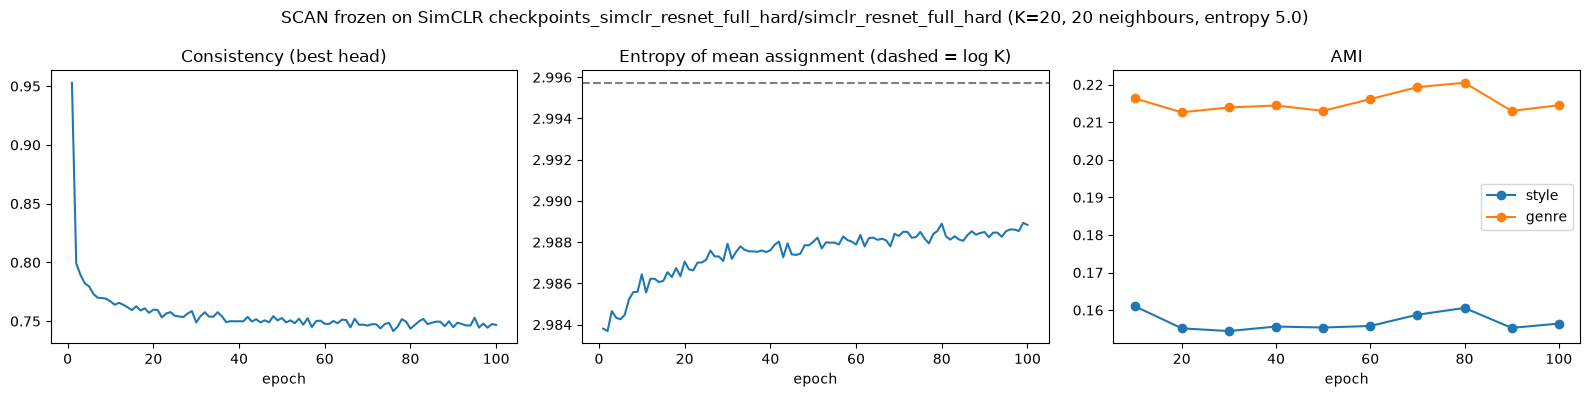

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
evals = scan_log.dropna(subset=["ami_style"])
axes[0].plot(scan_log["epoch"], scan_log["consistency"]);   axes[0].set(title="Consistency (best head)", xlabel="epoch")
axes[1].plot(scan_log["epoch"], scan_log["entropy"]);       axes[1].axhline(math.log(K), color="grey", linestyle="--")
axes[1].set(title="Entropy of mean assignment (dashed = log K)", xlabel="epoch")
axes[2].plot(evals["epoch"], evals["ami_style"], marker="o", label="style")
axes[2].plot(evals["epoch"], evals["ami_genre"], marker="o", label="genre")
axes[2].set(title="AMI", xlabel="epoch"); axes[2].legend()
fig.suptitle(RUN_NAME)
plt.tight_layout()
plt.show()

# 3. Self-labelling

Each step: predictions on a **weak** view (frozen: the clean embedding) decide the pseudo-labels; only confident ones (`max p > CONFIDENCE`) are used, and the best head is trained with cross-entropy on a **strong** view of the same paintings.
The cross-entropy is weighted by `1 / count` of each pseudo-label in the batch, so big clusters do not swallow the small ones.

In [46]:
self_log = []
self_labels = scan_labels

if SELF_LABEL:
    heads.heads[best_head].load_state_dict(scan_head_state)        # start from SCAN, not from a previous self-labelling run
    if scan_encoder_state is not None:
        encoder.load_state_dict(scan_encoder_state)
    for i, head in enumerate(heads.heads):          # keep only the best head
        head.requires_grad_(i == best_head)
    params = list(heads.heads[best_head].parameters()) + (list(encoder.parameters()) if MODE == "finetune" else [])
    optimizer = torch.optim.Adam(params, lr=LR, weight_decay=1e-4)
    print(f"confident before self-labelling: {(scan_probs.max(axis=1) > CONFIDENCE).mean():.1%} of paintings")
    good_head = {k: v.clone() for k, v in scan_head_state.items()}   # rollback point (label-free check below)

    for epoch in tqdm(range(1, SELF_EPOCHS + 1), desc="self-label epochs"):
        set_train()
        loss_sum, steps = 0.0, 0
        order = rng.permutation(n_paintings)
        for b in tqdm(range(n_batches), desc=f"epoch {epoch}", leave=False, disable=MODE == "frozen"):
            positions = order[b * HEAD_BATCH:(b + 1) * HEAD_BATCH]
            with torch.no_grad():
                probs = F.softmax(heads(features_of(positions, "weak"))[best_head], dim=1)
            confidence, target = probs.max(dim=1)
            mask = confidence > CONFIDENCE
            if mask.sum() < 2:
                continue
            counts = torch.bincount(target[mask], minlength=K).float()
            weight = torch.where(counts > 0, 1.0 / counts, torch.zeros_like(counts))
            weight = weight / weight.sum() * (counts > 0).sum()

            logits = heads(features_of(positions[mask.cpu().numpy()], "strong"))[best_head]
            loss = F.cross_entropy(logits, target[mask], weight=weight)

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item()
            steps += 1

        if EVAL_EVERY and (epoch % EVAL_EVERY == 0 or epoch == SELF_EPOCHS):
            self_probs = predict(best_head)
            self_labels = self_probs.argmax(axis=1)
            row = {"epoch": epoch, "loss": loss_sum / max(steps, 1), "confident": (self_probs.max(axis=1) > CONFIDENCE).mean(),
                   "ami_style": ami(self_labels, "style"), "ami_genre": ami(self_labels, "genre"),
                   "clusters_used": len(np.unique(self_labels))}
            self_log.append(row)
            print(f"epoch {epoch}: CE {row['loss']:.3f} | confident {row['confident']:.1%} | "
                  f"AMI style {row['ami_style']:.3f} genre {row['ami_genre']:.3f} | {row['clusters_used']} clusters used")
            if row["clusters_used"] < MIN_CLUSTERS * K:          # collapse: big clusters are swallowing the small ones
                heads.heads[best_head].load_state_dict(good_head)
                print(f"collapse ({row['clusters_used']} < {MIN_CLUSTERS:.0%} of {K} clusters): rolled back to the last good head, stopping")
                break
            good_head = {k: v.clone() for k, v in heads.heads[best_head].state_dict().items()}
    self_labels = predict(best_head).argmax(axis=1)
    self_log = pd.DataFrame(self_log)

confident before self-labelling: 20.2% of paintings


self-label epochs:   0%|          | 0/50 [00:00<?, ?it/s]

epoch 10: CE 0.019 | confident 87.3% | AMI style 0.048 genre 0.080 | 5 clusters used
collapse (5 < 80% of 20 clusters): rolled back to the last good head, stopping


# Evaluation

All three clusterings of the **same** paintings with the same `K`: K-means on the SimCLR features (before SCAN), SCAN, SCAN + self-labelling.

The silhouette is computed in the encoder features (the SimCLR ones in `frozen` mode; the fine-tuned encoder's in `finetune` mode), so it is only a rough guide for SCAN, whose clusters are drawn by the heads; NMI / AMI / ARI are directly comparable.

In [47]:
final_features = simclr_features if MODE == "frozen" else make_preprocess().fit_transform(embed_all(encoder).numpy())

candidates = [(f"K-means on {REPR_NAME}", kmeans_labels, simclr_features), ("SCAN", scan_labels, final_features)]
if SELF_LABEL:
    candidates.append(("SCAN + self-label", self_labels, final_features))

rows = []
for name, pred, space in candidates:
    row = {"method": name, "clusters used": len(np.unique(pred)),
           "largest": f"{np.bincount(pred).max() / len(pred):.1%}"}
    row["silhouette"] = silhouette_score(space, pred, sample_size=min(10_000, len(pred)), random_state=SEED) \
        if len(np.unique(pred)) > 1 else np.nan
    for column in LABEL_COLUMNS:
        known = meta[column].notna().to_numpy()
        row[f"NMI {column}"] = normalized_mutual_info_score(meta[column][known], pred[known])
        row[f"AMI {column}"] = adjusted_mutual_info_score(meta[column][known], pred[known])
        row[f"ARI {column}"] = adjusted_rand_score(meta[column][known], pred[known])
    rows.append(row)
display(pd.DataFrame(rows).set_index("method").round(3).T)

labels = self_labels if SELF_LABEL else scan_labels

method,K-means on SimCLR checkpoints_simclr_resnet_full_hard/simclr_resnet_full_hard,SCAN,SCAN + self-label
clusters used,20,20,20
largest,6.1%,6.5%,6.5%
silhouette,0.083,0.072,0.072
NMI style,0.16,0.161,0.161
AMI style,0.156,0.156,0.156
ARI style,0.044,0.043,0.043
NMI genre,0.21,0.216,0.216
AMI genre,0.209,0.215,0.215
ARI genre,0.101,0.111,0.111
NMI artist,0.225,0.226,0.226


c:\Users\MatG\Desktop\UniStuff\MAGI\Semestr II\UczenieNienadzorowane\Project\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


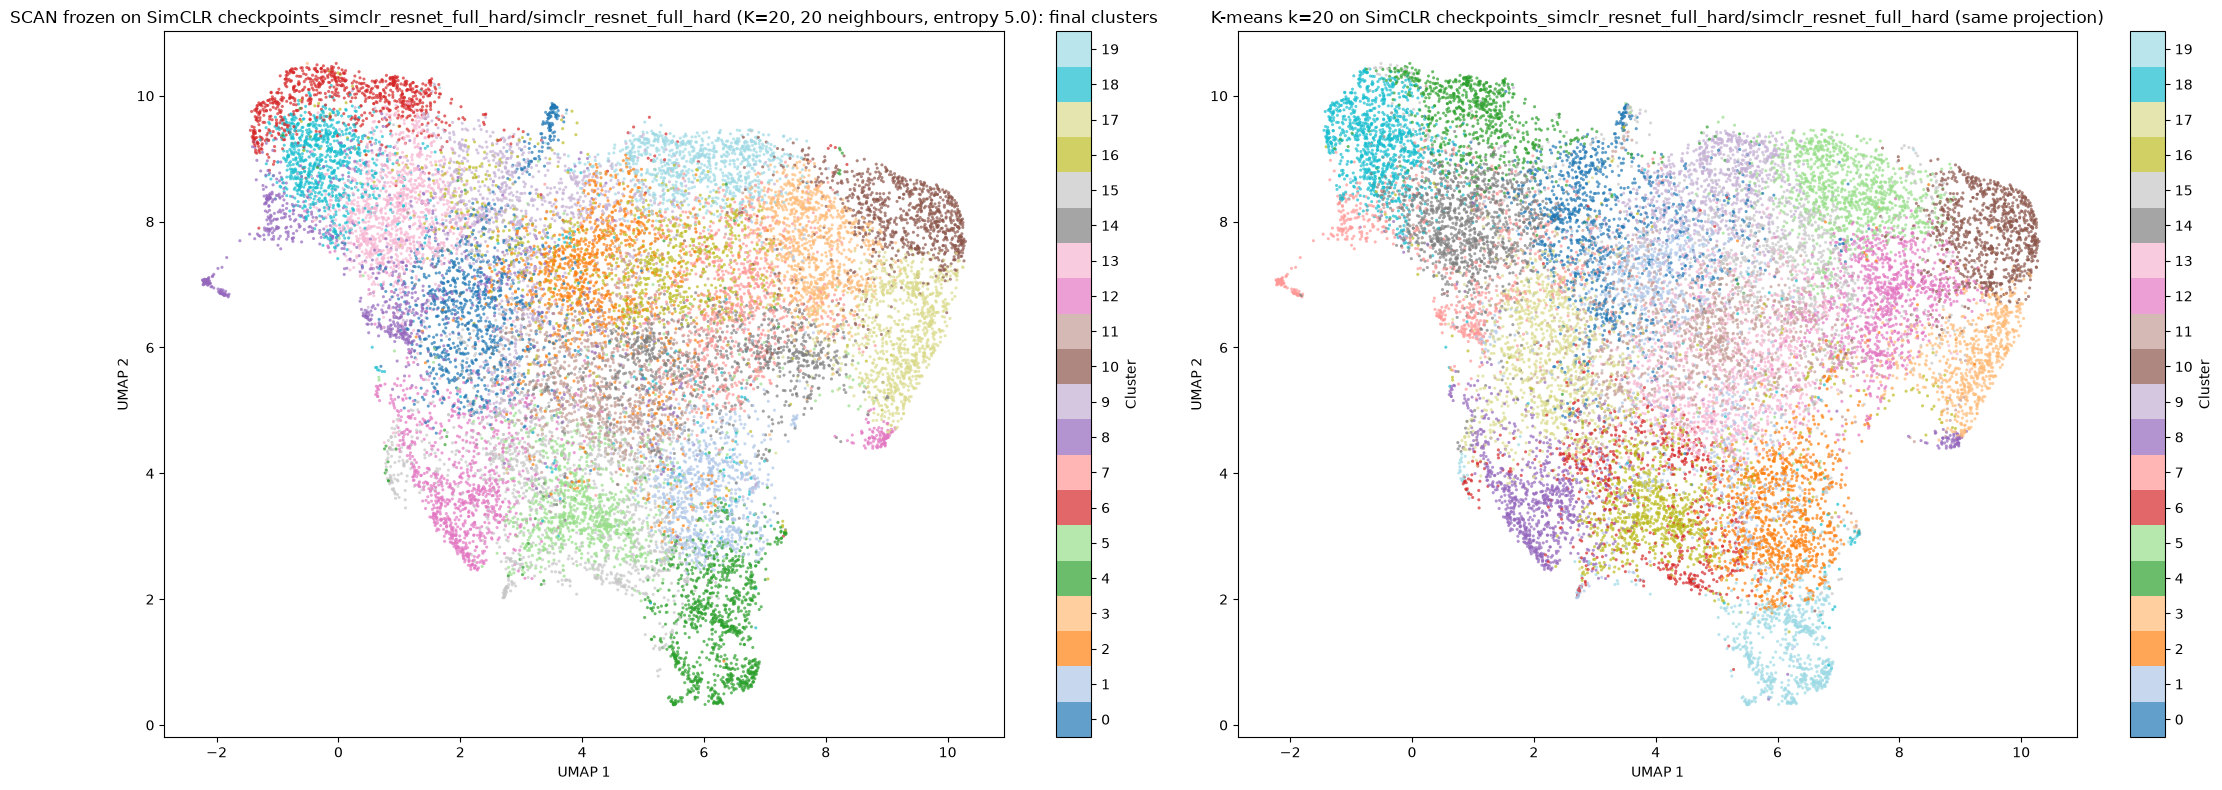

In [48]:
embedding_2d, idx_2d = umap_project(final_features, seed=SEED)
fig, axes = plt.subplots(1, 2, figsize=(22, 8))
plot_clusters_2d(embedding_2d, labels[idx_2d], title=f"{RUN_NAME}: final clusters", ax=axes[0])
plot_clusters_2d(embedding_2d, kmeans_labels[idx_2d], title=f"K-means k={K} on {REPR_NAME} (same projection)", ax=axes[1])
plt.tight_layout()
plt.show()

In [49]:
# What each cluster is "about": most common genre / style and their shares
def top(s: pd.Series):
    return s.value_counts().index[0] if s.notna().any() else None

def top_share(s: pd.Series):
    return s.value_counts(normalize=True).iloc[0] if s.notna().any() else np.nan

summary = (
    pd.DataFrame({"cluster": labels, "genre": meta["genre"], "style": meta["style"]})
    .groupby("cluster")
    .agg(size=("genre", "size"),
         top_genre=("genre", top), top_genre_share=("genre", top_share),
         top_style=("style", top), top_style_share=("style", top_share))
    .sort_values("size", ascending=False)
)
display(summary.round(2))

,size,top_genre,top_genre_share,top_style,top_style_share
cluster,,,,,
15,5359,abstract,0.22,art nouveau (modern),0.14
2,4481,genre painting,0.26,impressionism,0.08
12,4459,sketch and study,0.33,expressionism,0.12
13,4366,landscape,0.66,impressionism,0.44
11,4292,genre painting,0.16,expressionism,0.15
9,4267,landscape,0.27,realism,0.15
4,4267,abstract,0.69,color field painting,0.15
5,4219,genre painting,0.14,art nouveau (modern),0.16
18,4102,landscape,0.56,impressionism,0.26


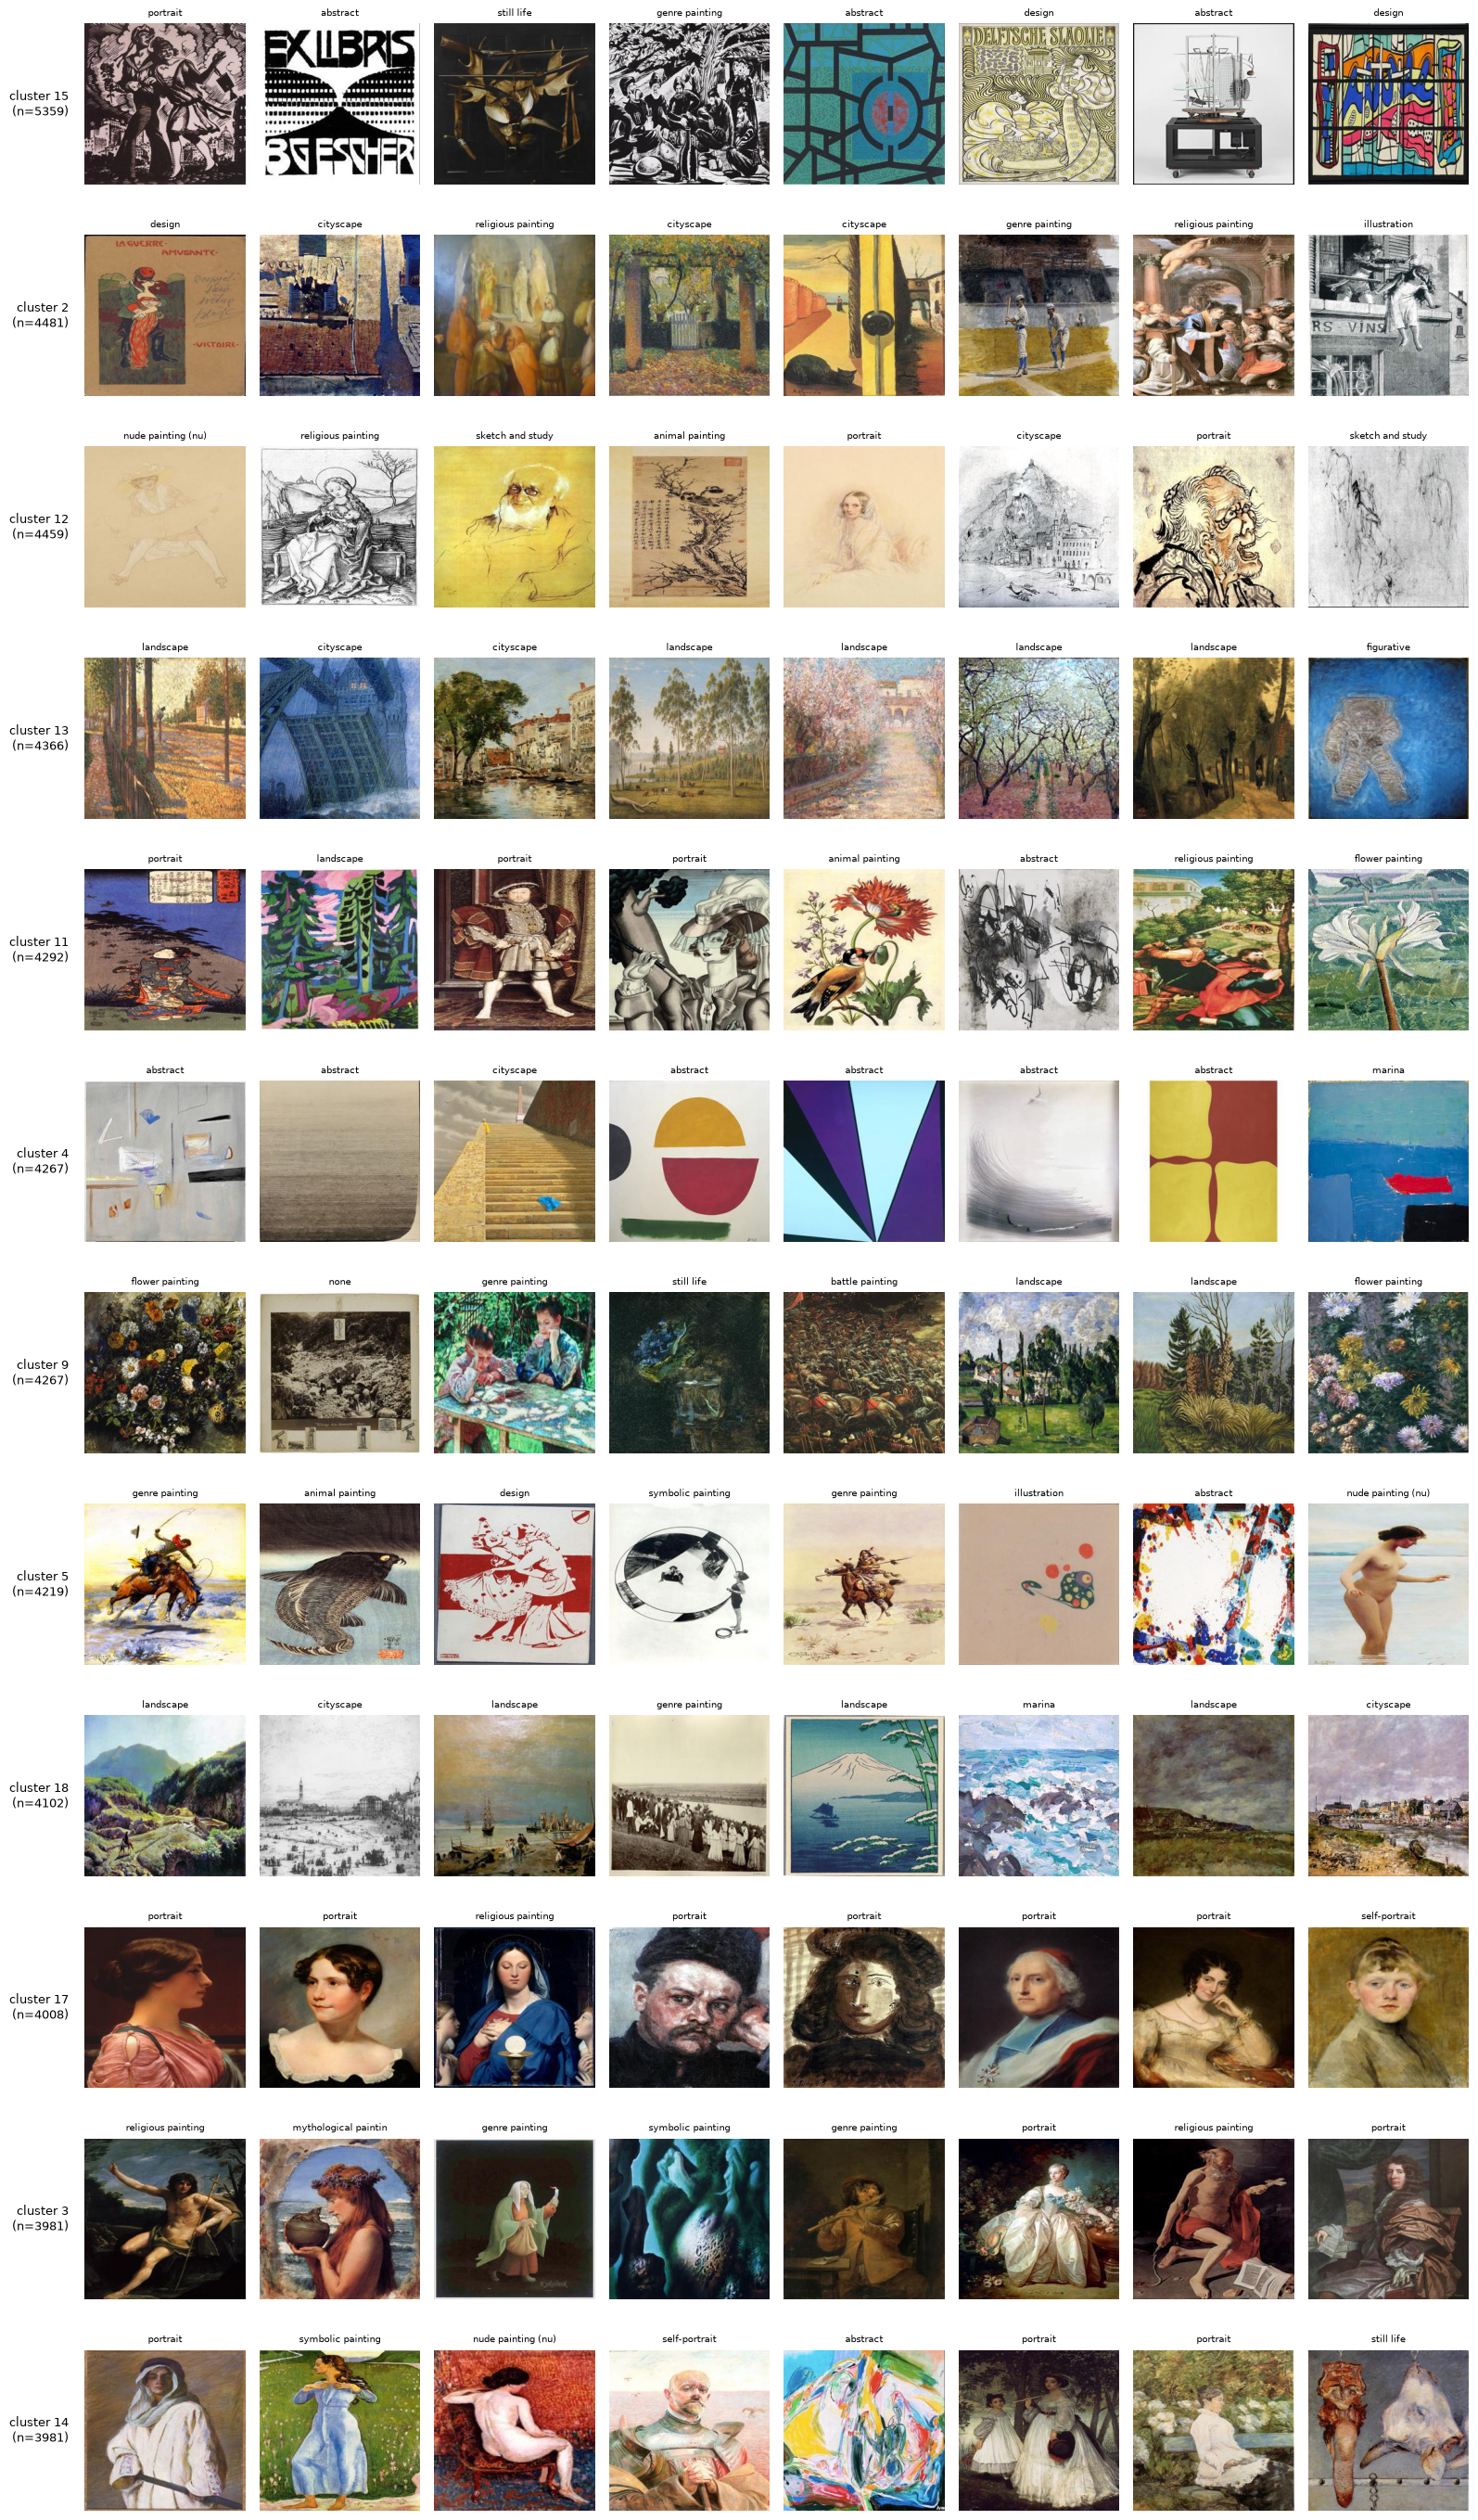

In [50]:
largest = summary.index[:SHOW_CLUSTERS]
rows_shown = np.flatnonzero(np.isin(labels, largest))
plot_cluster_samples(ds_cluster.select(rows_shown), labels[rows_shown], n_per_cluster=8,
                     captions=meta["genre"].iloc[rows_shown].reset_index(drop=True), seed=SEED)

In [51]:
# Reload: heads = ClusterHeads(512, K, 1, ckpt["config"]["head_hidden"]); heads.heads[0].load_state_dict(ckpt["head"])
#         (finetune mode: also encoder.load_state_dict(ckpt["encoder"]); frozen mode: the encoder is the SimCLR one)
if SAVE_TO is not None:
    Path(SAVE_TO).parent.mkdir(parents=True, exist_ok=True)
    torch.save({
        "config": {
            "source": SOURCE, "simclr_checkpoint": str(SIMCLR_CHECKPOINT) if SOURCE == "simclr" else None,
            "backbone": simclr_cfg["backbone"], "img_size": IMG_SIZE, "pca_dim": PCA_DIM, "mode": MODE, "k": K,
            "head_hidden": HEAD_HIDDEN if MODE == "frozen" else 0, "n_views": N_VIEWS,
            "n_neighbors": N_NEIGHBORS, "entropy_weight": ENTROPY_WEIGHT, "scan_epochs": SCAN_EPOCHS,
            "self_label": SELF_LABEL, "self_epochs": SELF_EPOCHS, "confidence": CONFIDENCE,
            "split": SPLIT, "n_paintings": N_PAINTINGS, "seed": SEED,
        },
        "head": heads.heads[best_head].state_dict(),
        "encoder": encoder.state_dict() if MODE == "finetune" else None,
        "labels": labels,
        "scan_log": scan_log.to_dict(orient="list"),
        "self_log": self_log.to_dict(orient="list") if SELF_LABEL else None,
    }, SAVE_TO)
    print(f"saved {SAVE_TO}")